In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

orders = pd.read_csv("data/olist_orders_dataset.csv")
customers = pd.read_csv("data/olist_customers_dataset.csv")
payments = pd.read_csv("data/olist_order_payments_dataset.csv")
reviews = pd.read_csv("data/olist_order_reviews_dataset.csv")
items = pd.read_csv("data/olist_order_items_dataset.csv")
products = pd.read_csv("data/olist_products_dataset.csv")

In [35]:
# Conversão da data
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"], errors="coerce")

# Selecionando pedidos entregues
delivered = orders[orders["order_status"] == "delivered"].copy()

# Associando os pedidos aos clientes únicos
delivered = delivered.merge(customers[["customer_id", "customer_unique_id"]], on="customer_id", how="left")
delivered = delivered.dropna(subset=["customer_unique_id", "order_purchase_timestamp"])

# Data de referência para calcular a recência
reference_date = (delivered["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1))

In [36]:
rf = delivered.groupby("customer_unique_id").agg(last_purchase=("order_purchase_timestamp", "max"), frequency=("order_id", "nunique"))

# Recency: dias desde a última compra
rf["recency"] = (reference_date - rf["last_purchase"]).dt.days
rf = rf.drop(columns=["last_purchase"])

In [37]:
# Soma dos pagamentos de cada pedido
payment_order = payments.groupby("order_id").agg(order_payment=("payment_value", "sum"))

# Associação dos pagamentos aos clientes
monetary = (delivered[["order_id", "customer_unique_id"]].merge(payment_order, on="order_id", how="left").groupby("customer_unique_id")["order_payment"]
            .sum(min_count=1).rename("monetary"))

# Unindo as características
features = rf.join(monetary)
features["monetary"] = features["monetary"].fillna(0)

# Ticket médio
features["average_ticket"] = (features["monetary"] / features["frequency"])

In [38]:
# Média das avaliações de cada pedido
reviews_order = reviews.groupby("order_id")["review_score"].mean()

# Média das avaliações por cliente
average_review = (delivered[["order_id", "customer_unique_id"]].merge(reviews_order, left_on="order_id", right_index=True, how="left")
                 .groupby("customer_unique_id")["review_score"].mean().rename("average_review"))

# Diversidade de categorias adquiridas
items_products = items.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
items_customers = delivered[["order_id", "customer_unique_id"]].merge(items_products[["order_id", "product_category_name"]],on="order_id",how="left")
product_diversity = (items_customers.groupby("customer_unique_id")["product_category_name"].nunique().rename("product_diversity"))

# Incorporando as novas características
features = features.join(average_review)
features = features.join(product_diversity)
features["product_diversity"] = (features["product_diversity"].fillna(0))

print(features.head())

                                  frequency  recency  monetary  \
customer_unique_id                                               
0000366f3b9a7992bf8c76cfdf3221e2          1      111    141.90   
0000b849f77a49e4a4ce2b2a4ca5be3f          1      114     27.19   
0000f46a3911fa3c0805444483337064          1      537     86.22   
0000f6ccb0745a6a4b88665a16c9f078          1      321     43.62   
0004aac84e0df4da2b147fca70cf8255          1      288    196.89   

                                  average_ticket  average_review  \
customer_unique_id                                                 
0000366f3b9a7992bf8c76cfdf3221e2          141.90             5.0   
0000b849f77a49e4a4ce2b2a4ca5be3f           27.19             4.0   
0000f46a3911fa3c0805444483337064           86.22             3.0   
0000f6ccb0745a6a4b88665a16c9f078           43.62             4.0   
0004aac84e0df4da2b147fca70cf8255          196.89             5.0   

                                  product_diversity  
custom

In [39]:
# Seleção dos atributos
feature_cols = ["recency","frequency","monetary","average_ticket","average_review","product_diversity"]

X = features[feature_cols].copy()

# Transformação logarítmica em atributos assimétricos
log_cols = ["recency","frequency","monetary","average_ticket","product_diversity"]

X[log_cols] = np.log1p(X[log_cols])

# Tratamento dos valores ausentes
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

# Padronização
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

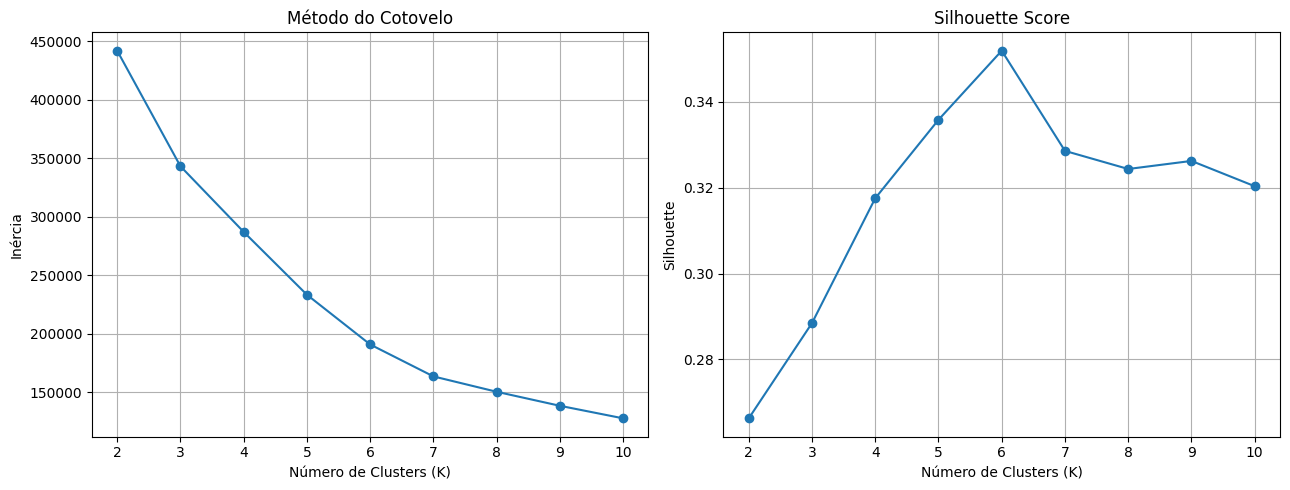

In [40]:
inertias = []
silhouettes = []

k_values = range(2, 11)

for k in k_values:

    model = KMeans(n_clusters=k, random_state=42, n_init=20)

    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)

    # Amostragem para reduzir o custo computacional
    sil = silhouette_score(X_scaled, labels, sample_size=min(5000, len(X_scaled)), random_state=42)

    silhouettes.append(sil)

# Visualização
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].plot(list(k_values), inertias, marker="o")
ax[0].set_title("Método do Cotovelo")
ax[0].set_xlabel("Número de Clusters (K)")
ax[0].set_ylabel("Inércia")
ax[0].grid(True)

ax[1].plot(list(k_values), silhouettes, marker="o")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Número de Clusters (K)")
ax[1].set_ylabel("Silhouette")
ax[1].grid(True)

plt.tight_layout()
plt.show()

In [41]:
# Escolha inicial baseada no Silhouette Score
best_k = list(k_values)[np.argmax(silhouettes)]
print("Número de clusters escolhido:", best_k)

# Treinamento final
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=20)

features["cluster"] = kmeans.fit_predict(X_scaled)

Número de clusters escolhido: 6


In [42]:
labels = features["cluster"]

silhouette = silhouette_score(X_scaled, labels, sample_size=min(10000, len(X_scaled)), random_state=42)
db_index = davies_bouldin_score(X_scaled, labels)
ch_index = calinski_harabasz_score(X_scaled, labels)

print(f"Silhouette Score: {silhouette:.4f}")
print(f"Davies-Bouldin Index: {db_index:.4f}")
print(f"Calinski-Harabasz Index: {ch_index:.4f}")

Silhouette Score: 0.3493
Davies-Bouldin Index: 0.8425
Calinski-Harabasz Index: 36093.3772


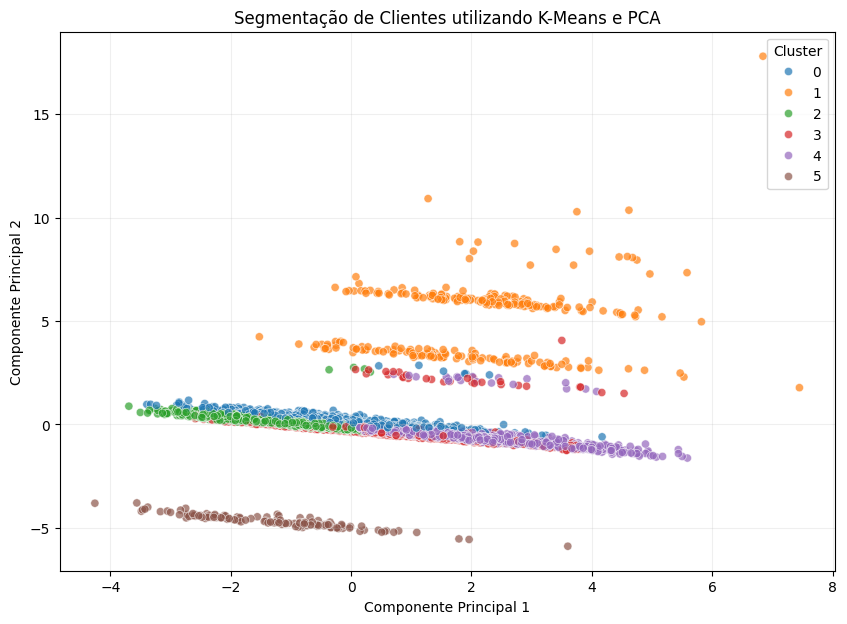

Variância explicada: 0.5689873325229459


In [43]:
# Redução de dimensionalidade
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Criando DataFrame para visualização
df_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])

df_pca["cluster"] = features["cluster"].values

# Amostragem para facilitar a visualização
df_plot = df_pca.sample(min(10000, len(df_pca)), random_state=42)

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df_plot, x="PC1", y="PC2", hue="cluster", palette="tab10", s=35, alpha=0.7)
plt.title("Segmentação de Clientes utilizando K-Means e PCA")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend(title="Cluster")
plt.grid(alpha=0.2)
plt.show()

# Variância explicada
print("Variância explicada:", pca.explained_variance_ratio_.sum())

In [44]:
# Características utilizadas no modelo
cluster_profile = features.groupby("cluster")[feature_cols].median()

# Quantidade de clientes por grupo
cluster_sizes = features["cluster"].value_counts().sort_index()
cluster_profile.insert(0, "number_of_customers", cluster_sizes)
cluster_profile["percentage"] = (cluster_sizes / len(features) * 100)

print(cluster_profile.round(2))

         number_of_customers  recency  frequency  monetary  average_ticket  \
cluster                                                                      
0                      13226     35.0        1.0    101.04          101.04   
1                       2796    199.0        2.0    225.53          109.94   
2                      36503    269.0        1.0     64.10           64.10   
3                      13184    218.0        1.0    118.13          118.13   
4                      26389    252.0        1.0    212.02          212.02   
5                       1260    262.0        1.0    115.59          115.45   

         average_review  product_diversity  percentage  
cluster                                                 
0                  5.00                1.0       14.17  
1                  4.67                2.0        2.99  
2                  5.00                1.0       39.10  
3                  1.00                1.0       14.12  
4                  5.00          